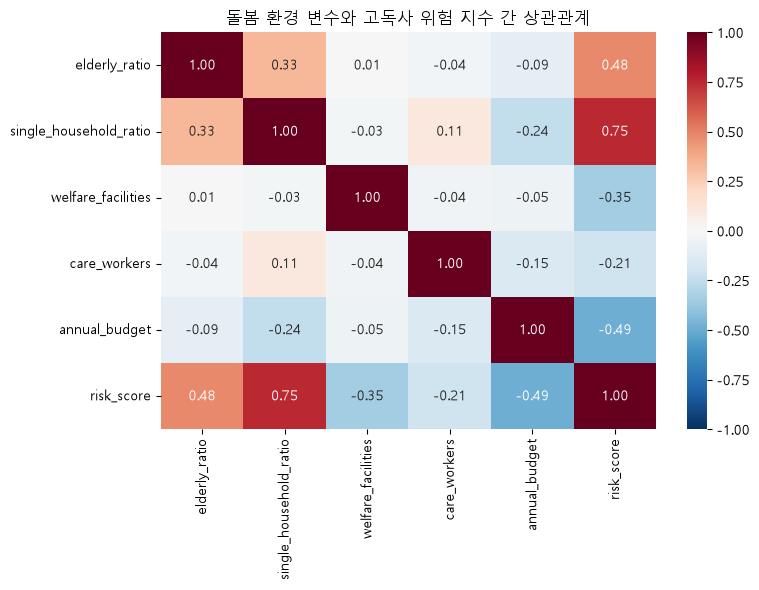

C:\Users\lukej\AppData\Local\Temp\ipykernel_12944\2734242010.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=features, palette="viridis")


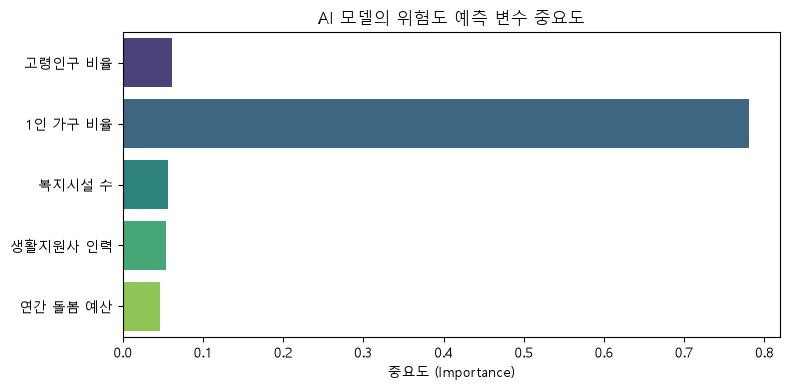

In [3]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 한글 폰트 설정 (Windows 기준: 맑은 고딕 / Mac 기준: AppleGothic)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

df = pd.read_csv("../data/processed/merged_care_dataset.csv")
model = joblib.load("../model/policy_effect_model.joblib")

# 1. 변수 간 상관관계 히트맵
plt.figure(figsize=(8, 6))
numeric_cols = [
    "elderly_ratio",
    "single_household_ratio",
    "welfare_facilities",
    "care_workers",
    "annual_budget",
    "risk_score",
]
corr = df[numeric_cols].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("돌봄 환경 변수와 고독사 위험 지수 간 상관관계")
plt.tight_layout()
plt.savefig("../data/processed/eda_heatmap.png", dpi=150)
plt.show()

# 2. AI 모델의 변수 중요도(Feature Importance) 시각화
features = [
    "고령인구 비율",
    "1인 가구 비율",
    "복지시설 수",
    "생활지원사 인력",
    "연간 돌봄 예산",
]
importances = model.feature_importances_

plt.figure(figsize=(8, 4))
sns.barplot(x=importances, y=features, palette="viridis")
plt.title("AI 모델의 위험도 예측 변수 중요도")
plt.xlabel("중요도 (Importance)")
plt.tight_layout()
plt.savefig("../data/processed/feature_importance.png", dpi=150)
plt.show()